<a href="https://colab.research.google.com/github/411221059/Analitik-dan-Visualisasi-data/blob/main/Pertemuan9-1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sqlite3
import pandas as pd

# Membuat dan menghubungkan ke database SQLite
conn = sqlite3.connect('perpustakaan.db')
cursor = conn.cursor()

# ==============================================================
# 1. PEMBUATAN TABEL
# ==============================================================
# Tabel Buku
cursor.execute('''
CREATE TABLE IF NOT EXISTS buku (
    id INTEGER PRIMARY KEY,
    judul TEXT,
    penulis TEXT,
    tahun INTEGER
)
''')

# Tabel Anggota
cursor.execute('''
CREATE TABLE IF NOT EXISTS anggota (
    id INTEGER PRIMARY KEY,
    nama TEXT,
    email TEXT
)
''')

# Tabel Peminjaman
cursor.execute('''
CREATE TABLE IF NOT EXISTS peminjaman (
    id INTEGER PRIMARY KEY,
    id_anggota INTEGER,
    id_buku INTEGER,
    tgl_pinjam TEXT,
    tgl_kembali TEXT,
    FOREIGN KEY(id_anggota) REFERENCES anggota(id),
    FOREIGN KEY(id_buku) REFERENCES buku(id)
)
''')

# ==============================================================
# a. INSERT DATA BUKU & ANGGOTA
# ==============================================================
buku_data = [
    (1, 'Laskar Pelangi', 'Andrea Hirata', 2005),
    (2, 'Bumi Manusia', 'Pramoedya Ananta Toer', 1980),
    (3, 'Filosofi Teras', 'Henry Manampiring', 2018),
    (4, 'Cantik Itu Luka', 'Eka Kurniawan', 2002),
    (5, 'Atomic Habits', 'James Clear', 2018)
]
# Menggunakan OR REPLACE agar tidak error jika dijalankan ulang
cursor.executemany('INSERT OR REPLACE INTO buku VALUES (?, ?, ?, ?)', buku_data)

anggota_data = [
    (1, 'Budi Santoso', 'budi@email.com'),
    (2, 'Siti Aminah', 'siti@email.com'),
    (3, 'Andi Wijaya', 'andi@email.com')
]
cursor.executemany('INSERT OR REPLACE INTO anggota VALUES (?, ?, ?)', anggota_data)

# ==============================================================
# b. INSERT TRANSAKSI PEMINJAMAN (1 data tgl_kembali bernilai NULL)
# ==============================================================
peminjaman_data = [
    (1, 1, 1, '2023-10-01', '2023-10-08'),
    (2, 2, 3, '2023-10-05', '2023-10-10'),
    (3, 1, 4, '2023-10-15', '2023-10-22'),
    (4, 3, 2, '2023-10-20', None) # Data ini belum dikembalikan
]
cursor.executemany('INSERT OR REPLACE INTO peminjaman VALUES (?, ?, ?, ?, ?)', peminjaman_data)
conn.commit()

# ==============================================================
# c. DAFTAR PEMINJAMAN LENGKAP (JOIN)
# ==============================================================
query_join = '''
SELECT p.id as id_pinjam, a.nama as nama_anggota, b.judul as judul_buku, p.tgl_pinjam, p.tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku b ON p.id_buku = b.id
'''
print("--- 1c. Daftar Peminjaman Lengkap ---")
df_join_display = pd.read_sql_query(query_join, conn)
display(df_join_display) # Fungsi bawaan Colab untuk menampilkan tabel dengan rapi

# ==============================================================
# d. TOTAL BUKU YANG DIPINJAM MASING-MASING ANGGOTA (GROUP BY)
# ==============================================================
query_groupby = '''
SELECT a.nama as nama_anggota, COUNT(p.id) as total_buku_dipinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id
'''
print("\n--- 1d. Total Buku Dipinjam Per Anggota ---")
df_groupby_display = pd.read_sql_query(query_groupby, conn)
display(df_groupby_display)

--- 1c. Daftar Peminjaman Lengkap ---


,id_pinjam,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Budi Santoso,Laskar Pelangi,2023-10-01,2023-10-08
1,2,Siti Aminah,Filosofi Teras,2023-10-05,2023-10-10
2,3,Budi Santoso,Cantik Itu Luka,2023-10-15,2023-10-22
3,4,Andi Wijaya,Bumi Manusia,2023-10-20,None



--- 1d. Total Buku Dipinjam Per Anggota ---


,nama_anggota,total_buku_dipinjam
0,Budi Santoso,2
1,Siti Aminah,1
2,Andi Wijaya,1


--- 2b. DataFrame dengan Eksplorasi Durasi ---


,id_pinjam,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,durasi_hari
0,1,Budi Santoso,Laskar Pelangi,2023-10-01,2023-10-08,7.0
1,2,Siti Aminah,Filosofi Teras,2023-10-05,2023-10-10,5.0
2,3,Budi Santoso,Cantik Itu Luka,2023-10-15,2023-10-22,7.0
3,4,Andi Wijaya,Bumi Manusia,2023-10-20,NaT,NaN


/tmp/ipykernel_765/403996619.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='nama_anggota', y='total_buku_dipinjam', data=df_agregasi, palette='Blues_d')


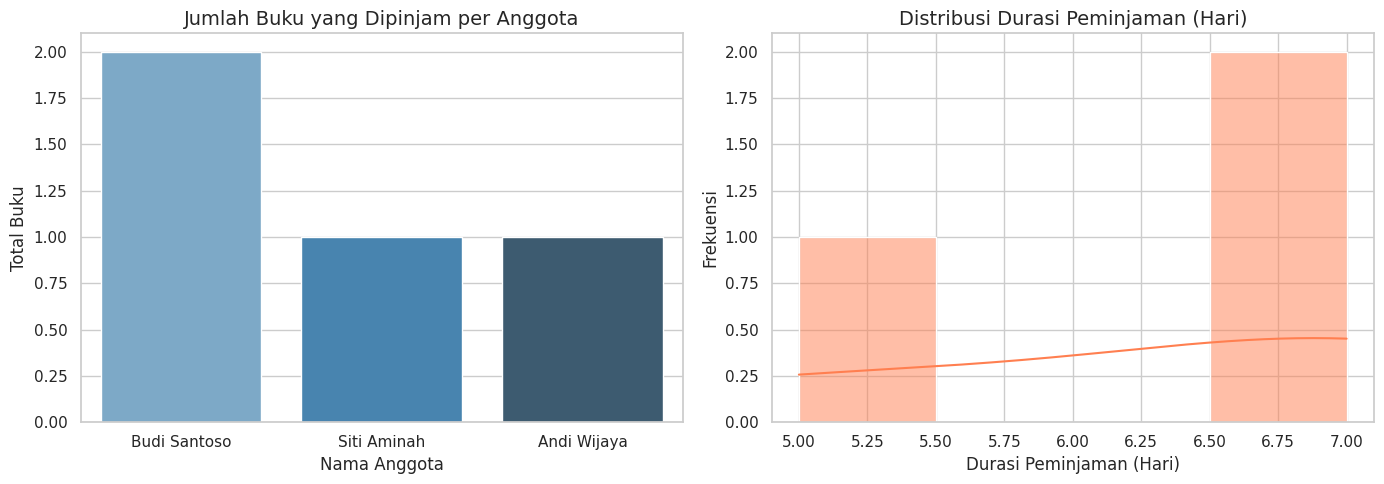

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================
# a. BUAT DATAFRAME DARI QUERY SQL
# ==============================================================
df_peminjaman = pd.read_sql_query(query_join, conn)
df_agregasi = pd.read_sql_query(query_groupby, conn)

# ==============================================================
# b. EKSPLORASI DATA: Menghitung Durasi Peminjaman (Dalam Hari)
# ==============================================================
# Konversi kolom teks ke tipe data datetime Pandas
df_peminjaman['tgl_pinjam'] = pd.to_datetime(df_peminjaman['tgl_pinjam'])
df_peminjaman['tgl_kembali'] = pd.to_datetime(df_peminjaman['tgl_kembali'])

# Menghitung durasi hari (Tanggal Kembali - Tanggal Pinjam)
# Hasil untuk data yang NULL (NaT) akan bernilai NaN (Not a Number)
df_peminjaman['durasi_hari'] = (df_peminjaman['tgl_kembali'] - df_peminjaman['tgl_pinjam']).dt.days

print("--- 2b. DataFrame dengan Eksplorasi Durasi ---")
display(df_peminjaman)

# ==============================================================
# c. VISUALISASI DATA
# ==============================================================
# Mengatur tema seaborn
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 5))

# Visualisasi 1: Diagram Batang (Jumlah Buku per Anggota)
plt.subplot(1, 2, 1)
sns.barplot(x='nama_anggota', y='total_buku_dipinjam', data=df_agregasi, palette='Blues_d')
plt.title('Jumlah Buku yang Dipinjam per Anggota', fontsize=14)
plt.xlabel('Nama Anggota', fontsize=12)
plt.ylabel('Total Buku', fontsize=12)

# Visualisasi 2: Histogram (Distribusi Durasi Peminjaman)
plt.subplot(1, 2, 2)
# dropna() digunakan untuk mengabaikan nilai NaN (buku yang belum dikembalikan)
sns.histplot(df_peminjaman['durasi_hari'].dropna(), bins=4, kde=True, color='coral')
plt.title('Distribusi Durasi Peminjaman (Hari)', fontsize=14)
plt.xlabel('Durasi Peminjaman (Hari)', fontsize=12)
plt.ylabel('Frekuensi', fontsize=12)

plt.tight_layout()
plt.show()

# Menutup koneksi database setelah semua proses selesai
conn.close()